# Affinity Propagation Clustering — Complete Tutorial
### Mathematical foundations, implementation, evaluation, and a bioinformatics example

**Level:** Intermediate to advanced  
**Libraries:** NumPy, pandas, Matplotlib, scikit-learn

**Learning goals**
- Understand exemplars, similarity, responsibility, availability, preference, and damping.
- Study the message-passing equations and a small educational implementation.
- Fit and visualize `sklearn.cluster.AffinityPropagation`.
- Investigate hyperparameters, convergence, metrics, and algorithm comparisons.
- Apply the workflow to synthetic gene-expression profiles while discussing scientific limitations.

> Affinity Propagation does not require the number of clusters as an input. It selects *exemplars*—actual observations that represent clusters. The number found depends strongly on the preference values and the similarity structure.

## 1. Imports and reproducibility

In [1]:
# Import numerical, tabular, plotting, and machine-learning tools.
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AffinityPropagation, KMeans, DBSCAN
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score, normalized_mutual_info_score, silhouette_score,
    davies_bouldin_score, calinski_harabasz_score, pairwise_distances
)
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.max_columns", 30)

## 2. What is Affinity Propagation?

Affinity Propagation (AP) treats every observation as a potential representative and exchanges messages between observations to identify good exemplars.

- **Similarity** \(s(i,k)\): how well observation \(k\) represents observation \(i\); larger is more similar.
- **Responsibility** \(r(i,k)\): how strongly \(i\) favors candidate \(k\), compared with alternative candidates.
- **Availability** \(a(i,k)\): how suitable \(k\) appears as an exemplar, considering support from other observations.
- **Preference**: the self-similarity that influences how likely observations are to become exemplars.
- **Damping**: a smoothing factor that can stabilize message updates and reduce oscillation.

### AP versus K-Means

| Property | Affinity Propagation | K-Means |
|---|---|---|
| Number of clusters | Emerges from preference and similarities | Specify `n_clusters` |
| Representative | Actual observation (exemplar) | Mean vector (centroid) |
| Core mechanism | Responsibility/availability messages | Assignment and centroid updates |
| Similarity | Supports custom similarity matrices | Commonly Euclidean distance |
| Memory | Typically \(O(n^2)\) | Usually more scalable for large datasets |
| Explicit noise labels | No standard `-1` mechanism | No standard `-1` mechanism |

AP is not automatically superior; it is a different modeling choice. Feature scaling, similarity design, and sensitivity analysis remain important.

## 3. Mathematical Foundations

### 3.1 Similarity Matrix

For \(n\) observations, Affinity Propagation (AP) uses a similarity matrix \(S \in \mathbb{R}^{n \times n}\). A common Euclidean-based similarity measure is the negative squared Euclidean distance:

$$
s(i,k) = -\|x_i - x_k\|_2^2
$$

Nearby observations have larger (less negative) similarity values. The diagonal entries \(s(k,k)\) represent the self-preferences of potential exemplars.

### 3.2 Responsibility

The responsibility message \(r(i,k)\) measures how strongly observation \(i\) favors candidate exemplar \(k\), relative to the other candidates:

$$
r(i,k) = s(i,k) -
\max_{k' \ne k}
\left\{
a(i,k') + s(i,k')
\right\}
$$

A larger responsibility indicates that candidate \(k\) is more suitable for observation \(i\) compared with alternative candidates.

### 3.3 Availability

The availability message \(a(i,k)\) measures how appropriate it is for observation \(i\) to select candidate \(k\) as its exemplar, considering the support from other observations.

For \(i \ne k\):

$$
a(i,k) =
\min\left(
0,\;
r(k,k) +
\sum_{i' \notin \{i,k\}}
\max(0,r(i',k))
\right)
$$

For the diagonal entries, where \(i=k\):

$$
a(k,k) =
\sum_{i' \ne k}
\max(0,r(i',k))
$$

The diagonal availability measures the accumulated positive support for candidate \(k\). Off-diagonal availability values are capped at zero.

### 3.4 Damping and Exemplar Selection

To reduce oscillations during message passing, AP applies a damping factor \(\lambda\):

$$
m^{(t)} =
\lambda m^{(t-1)}
+
(1-\lambda)\hat{m}^{(t)}
$$

where:

- \(m^{(t)}\) is the damped message at iteration \(t\).
- \(m^{(t-1)}\) is the message from the previous iteration.
- \(\hat{m}^{(t)}\) is the newly calculated message.
- \(\lambda\) is the damping factor.

A larger damping factor gives more weight to previous messages and may improve stability, although convergence can become slower.

Conceptually, observation \(k\) is considered an exemplar when:

$$
a(k,k) + r(k,k) > 0
$$

The final clustering procedure also depends on convergence checks and cluster-assignment logic implemented by the algorithm.

## 4. Create a synthetic dataset

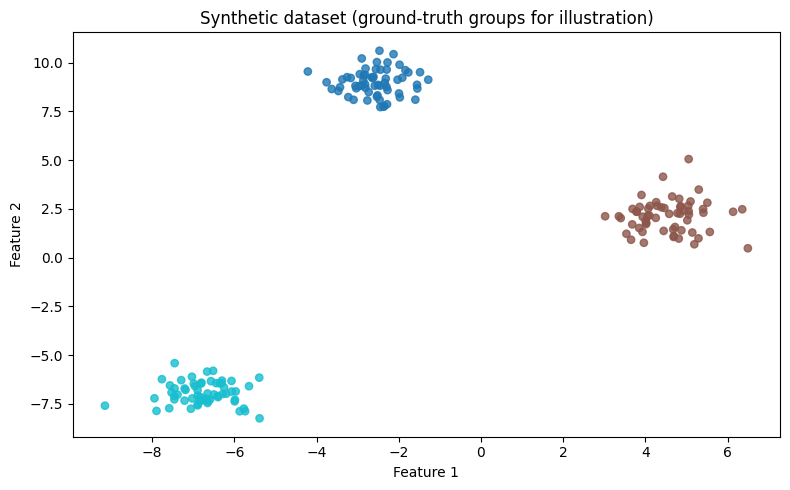

In [2]:
# Generate three compact groups with different centers.
X, y_true = make_blobs(
    n_samples=180, centers=3, cluster_std=[0.65, 0.8, 0.7],
    n_features=2, random_state=RANDOM_STATE
)

# Plot observations colored by their synthetic ground-truth labels.
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=y_true, cmap="tab10", s=28, alpha=0.8)
plt.title("Synthetic dataset (ground-truth groups for illustration)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()

## 5. Educational message-passing implementation

This simplified implementation demonstrates the responsibility and availability updates on a small similarity matrix. It is for learning—not a replacement for scikit-learn's convergence-tested estimator.

In [3]:
def educational_message_updates(S, n_iterations=20, damping=0.7):
    """Demonstrate simplified AP responsibility and availability updates."""
    S = np.asarray(S, dtype=float)
    if S.ndim != 2 or S.shape[0] != S.shape[1]:
        raise ValueError("S must be a square similarity matrix.")
    if not (0 <= damping < 1):
        raise ValueError("damping must be in [0, 1).")

    n = S.shape[0]
    R = np.zeros_like(S)  # Responsibility messages
    A = np.zeros_like(S)  # Availability messages

    for _ in range(n_iterations):
        # Responsibility: subtract the best competing candidate score.
        AS = A + S
        best_idx = np.argmax(AS, axis=1)
        best_val = AS[np.arange(n), best_idx]
        AS_without_best = AS.copy()
        AS_without_best[np.arange(n), best_idx] = -np.inf
        second_best = np.max(AS_without_best, axis=1)

        R_new = S - best_val[:, None]
        R_new[np.arange(n), best_idx] = (
            S[np.arange(n), best_idx] - second_best
        )

        # Availability: sum positive incoming responsibilities.
        positive_R = np.maximum(R_new, 0)
        A_new = positive_R.sum(axis=0)[None, :] - positive_R
        A_new = np.minimum(A_new, 0)
        np.fill_diagonal(
            A_new, positive_R.sum(axis=0) - np.diag(positive_R)
        )

        # Damping blends new messages with previous messages.
        R = damping * R + (1 - damping) * R_new
        A = damping * A + (1 - damping) * A_new

    return R, A

# Use a tiny subset so the message matrices remain interpretable.
X_tiny = X[:8]
S_tiny = -pairwise_distances(X_tiny, metric="sqeuclidean")
off_diag_mask = ~np.eye(len(S_tiny), dtype=bool)
np.fill_diagonal(S_tiny, np.median(S_tiny[off_diag_mask]))

R_tiny, A_tiny = educational_message_updates(
    S_tiny, n_iterations=30, damping=0.7
)
print("Similarity matrix shape:", S_tiny.shape)
print("Responsibility matrix:\n", np.round(R_tiny, 2))
print("Availability matrix:\n", np.round(A_tiny, 2))

Similarity matrix shape: (8, 8)
Responsibility matrix:
 [[-202.21 -198.62    0.23   -0.38   -0.23 -207.08 -252.94   -0.7 ]
 [-198.49 -202.08 -207.76 -206.16 -213.78   76.6  -106.74 -205.66]
 [   0.04 -207.89 -202.21   -0.22   -0.04 -216.48 -262.65   -0.52]
 [  -0.44 -206.35   -0.28 -202.27   -0.84 -214.44 -272.97    0.28]
 [  -0.19 -213.87    0.19   -0.74 -202.16 -222.84 -261.06   -1.2 ]
 [-206.95  116.14 -216.35 -214.25 -222.75 -202.08 -116.15 -213.56]
 [-146.07    9.4  -155.78 -166.03 -154.23   -9.4   -95.33 -170.13]
 [  -0.76 -205.85   -0.59    0.59   -1.31 -213.76 -277.07 -202.27]]
Availability matrix:
 [[  0.04   0.     0.     0.     0.     0.     0.     0.  ]
 [  0.   125.54   0.     0.     0.     0.     0.     0.  ]
 [  0.     0.     0.42   0.     0.     0.     0.     0.  ]
 [  0.     0.     0.     0.59   0.     0.     0.     0.  ]
 [  0.     0.     0.     0.     0.     0.     0.     0.  ]
 [  0.     0.     0.     0.     0.    76.6    0.     0.  ]
 [  0.     0.     0.     0.    

**Note on the equations:** The diagonal availability update is shown explicitly. For production analysis, use scikit-learn's tested implementation; this miniature exists to make the message-passing idea tangible.

## 6. Fit Affinity Propagation with scikit-learn

In [4]:
# Use median off-diagonal similarity as a transparent starting preference.
S = -pairwise_distances(X, metric="sqeuclidean")
off_diag = S[~np.eye(len(X), dtype=bool)]
preference = np.median(off_diag)

ap = AffinityPropagation(
    affinity="euclidean",       # scikit-learn computes Euclidean-based similarities
    preference=preference,
    damping=0.75,
    max_iter=500,
    convergence_iter=20,
    random_state=RANDOM_STATE,
)

start = time.perf_counter()
ap.fit(X)
fit_seconds = time.perf_counter() - start

labels_ap = ap.labels_
n_clusters_ap = len(np.unique(labels_ap))
n_exemplars = 0 if ap.cluster_centers_indices_ is None else len(ap.cluster_centers_indices_)

print(f"Clusters found: {n_clusters_ap}")
print(f"Exemplars found: {n_exemplars}")
print(f"Iterations run: {ap.n_iter_}")
print(f"Fit time: {fit_seconds:.4f} seconds")
print("Cluster sizes:")
print(pd.Series(labels_ap).value_counts().sort_index())

Clusters found: 3
Exemplars found: 3
Iterations run: 32
Fit time: 0.0124 seconds
Cluster sizes:
0    60
1    60
2    60
Name: count, dtype: int64


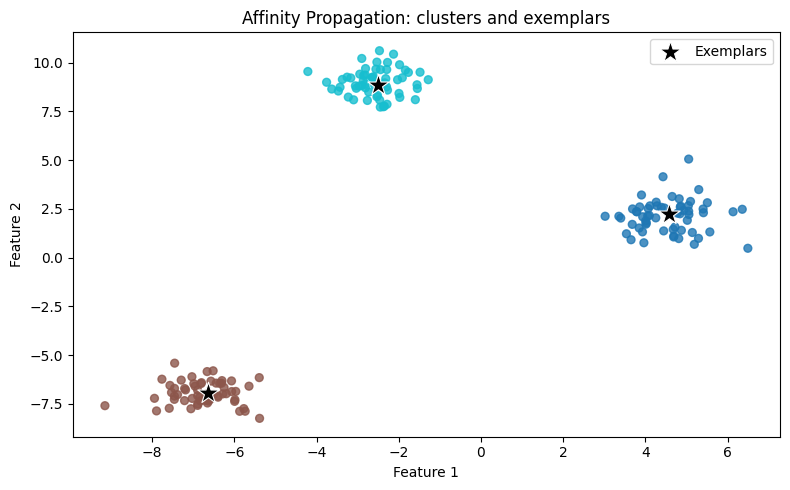

In [5]:
# Plot cluster assignments and mark exemplar observations.
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels_ap, cmap="tab10", s=32, alpha=0.8)
if ap.cluster_centers_indices_ is not None and len(ap.cluster_centers_indices_) > 0:
    exemplars = X[ap.cluster_centers_indices_]
    plt.scatter(
        exemplars[:, 0], exemplars[:, 1], marker="*", s=260,
        c="black", edgecolors="white", linewidths=0.8, label="Exemplars"
    )
plt.title("Affinity Propagation: clusters and exemplars")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Hyperparameter experiments

### 7.1 `preference`

More attractive self-preferences generally encourage more exemplars and often more clusters. The relationship depends on the data and similarity scale. Interpret preference relative to the feature representation.

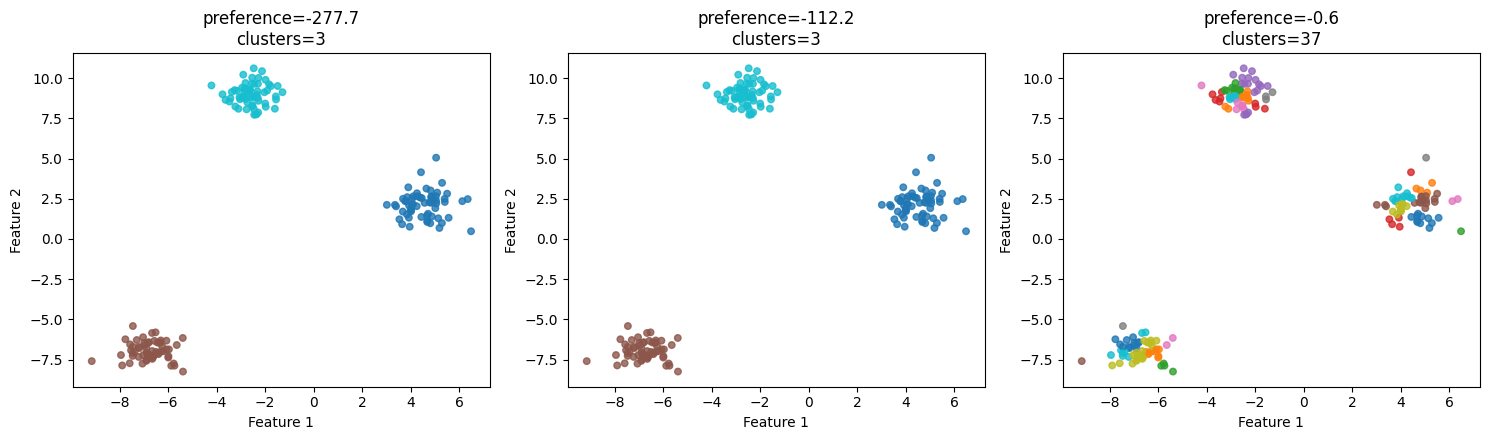

,preference,clusters,iterations
0,-277.680179,3,35
1,-112.177127,3,32
2,-0.635046,37,37


In [6]:
# Compare low, median, and high off-diagonal similarity preferences.
preference_values = [
    np.percentile(off_diag, 10),
    np.median(off_diag),
    np.percentile(off_diag, 90),
]
preference_results = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, pref in zip(axes, preference_values):
    model = AffinityPropagation(
        affinity="euclidean", preference=pref, damping=0.75,
        max_iter=500, convergence_iter=20, random_state=RANDOM_STATE
    ).fit(X)
    labels = model.labels_
    k = len(np.unique(labels))
    preference_results.append({
        "preference": pref, "clusters": k, "iterations": model.n_iter_
    })
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=22, alpha=0.8)
    ax.set_title(f"preference={pref:.1f}\nclusters={k}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()
pd.DataFrame(preference_results)

### 7.2 `damping`

Damping controls how strongly each iteration retains the previous message. In scikit-learn, it must satisfy \(0.5\leq\text{damping}<1\). Higher values may reduce oscillation but can require more iterations.

In [7]:
# Compare damping settings while holding other parameters fixed.
damping_results = []
for damping in [0.5, 0.6, 0.75, 0.9]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model = AffinityPropagation(
            affinity="euclidean", preference=preference, damping=damping,
            max_iter=500, convergence_iter=20, random_state=RANDOM_STATE
        ).fit(X)
    damping_results.append({
        "damping": damping,
        "clusters": len(np.unique(model.labels_)),
        "iterations": model.n_iter_,
        "warnings": " | ".join(str(w.message) for w in caught) or "None",
    })
pd.DataFrame(damping_results)

,damping,clusters,iterations,warnings
0,0.50,3,64,None
1,0.60,3,36,None
2,0.75,3,32,None
3,0.90,3,49,None


### 7.3 Iteration limits and convergence

`max_iter` is the hard iteration limit. `convergence_iter` controls how many consecutive iterations must show a stable exemplar set before convergence is declared. Always inspect warnings and iteration counts.

In [8]:
# Deliberately use a low iteration cap to illustrate diagnostics.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    limited_model = AffinityPropagation(
        affinity="euclidean", preference=preference, damping=0.75,
        max_iter=10, convergence_iter=10, random_state=RANDOM_STATE
    ).fit(X)

print("Iterations:", limited_model.n_iter_)
print("Reached iteration cap:", limited_model.n_iter_ >= limited_model.max_iter)
print("Warnings:")
for warning in caught:
    print("-", warning.message)

Iterations: 10
Reached iteration cap: True
Warnings:
- Affinity propagation did not converge, this model may return degenerate cluster centers and labels.


## 8. Evaluation metrics

No single score proves a clustering solution is correct.

- **Silhouette**: ranges from -1 to 1; larger often indicates better separation.
- **Davies–Bouldin**: lower is generally better.
- **Calinski–Harabasz**: higher is generally better.
- **ARI / NMI**: compare predicted clusters with reference labels; use only when such labels genuinely exist.

Internal metrics need at least two clusters and fewer clusters than samples.

In [9]:
def evaluate_clustering(X_values, labels, y_reference=None):
    """Compute common metrics, returning NaN when internal scores are undefined."""
    labels = np.asarray(labels)
    n_clusters = len(np.unique(labels))
    result = {
        "n_clusters": n_clusters,
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
        "ARI_vs_reference": np.nan,
        "NMI_vs_reference": np.nan,
    }
    if 2 <= n_clusters < len(labels):
        result["silhouette"] = silhouette_score(X_values, labels)
        result["davies_bouldin"] = davies_bouldin_score(X_values, labels)
        result["calinski_harabasz"] = calinski_harabasz_score(X_values, labels)
    if y_reference is not None:
        result["ARI_vs_reference"] = adjusted_rand_score(y_reference, labels)
        result["NMI_vs_reference"] = normalized_mutual_info_score(y_reference, labels)
    return result

evaluate_clustering(X, labels_ap, y_true)

{'n_clusters': 3,
 'silhouette': 0.89099532167996,
 'davies_bouldin': 0.15742263528271336,
 'calinski_harabasz': 6203.869009827196,
 'ARI_vs_reference': 1.0,
 'NMI_vs_reference': 1.0}

## 9. Compare AP, K-Means, and DBSCAN

In [10]:
# K-Means is given the known synthetic cluster count as a controlled baseline.
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X)
dbscan = DBSCAN(eps=0.8, min_samples=5).fit(X)
models = {
    "Affinity Propagation": labels_ap,
    "K-Means (k=3)": kmeans.labels_,
    "DBSCAN": dbscan.labels_,
}

comparison_rows = []
for name, labels in models.items():
    row = evaluate_clustering(X, labels, y_true)
    row["model"] = name
    row["cluster_sizes"] = dict(pd.Series(labels).value_counts().sort_index())
    comparison_rows.append(row)
comparison = pd.DataFrame(comparison_rows).set_index("model")
comparison

,n_clusters,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_reference,NMI_vs_reference,cluster_sizes
model,,,,,,,
Affinity Propagation,3,0.890995,0.157423,6203.86901,1.000000,1.000000,"{0: 60, 1: 60, 2: 60}"
K-Means (k=3),3,0.890995,0.157423,6203.86901,1.000000,1.000000,"{0: 60, 1: 60, 2: 60}"
DBSCAN,4,0.831420,1.318486,1346.00536,0.958285,0.941754,"{-1: 5, 0: 58, 1: 57, 2: 60}"


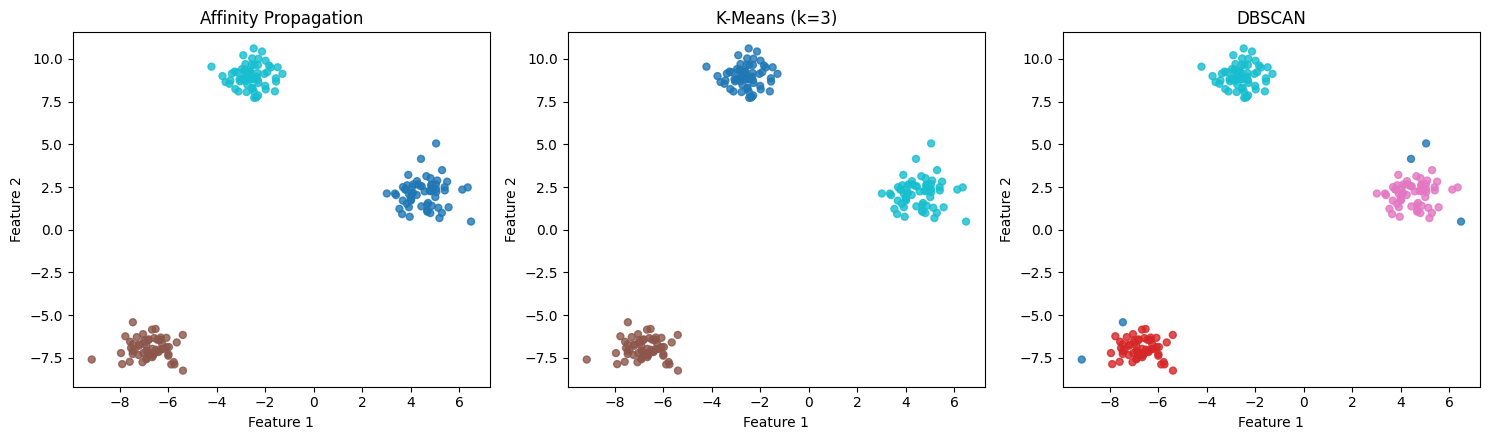

In [11]:
# Visual comparison on the same two-dimensional feature space.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, labels) in zip(axes, models.items()):
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=25, alpha=0.8)
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

**Interpret carefully:** DBSCAN assigns noise observations the label `-1`; this is not an ordinary cluster. AP has no equivalent standard noise-label mechanism. Compare metrics with the algorithms' different assumptions in mind.

## 10. Bioinformatics application: synthetic gene-expression profiles

This example uses **synthetic** expression-like values—not patient records or a real biological cohort. It demonstrates grouping samples by multivariate profiles. Real analyses require suitable normalization, batch-effect assessment, stability checks, and independent validation.

In [12]:
# Simulate 90 samples and 60 genes with three illustrative expression patterns.
n_samples = 90
n_genes = 60
n_groups = 3
group_labels = np.repeat(np.arange(n_groups), n_samples // n_groups)
expression = rng.normal(loc=0.0, scale=1.0, size=(n_samples, n_genes))

# Give each synthetic group a distinct block of genes with shifted values.
for group in range(n_groups):
    rows = np.where(group_labels == group)[0]
    start_gene = group * 12
    end_gene = start_gene + 12
    expression[rows, start_gene:end_gene] += 1.8

gene_names = [f"Gene_{i+1:03d}" for i in range(n_genes)]
sample_names = [f"Sample_{i+1:03d}" for i in range(n_samples)]
expression_df = pd.DataFrame(expression, index=sample_names, columns=gene_names)
expression_df.index.name = "Sample"

print("Expression matrix shape:", expression_df.shape)
expression_df.iloc[:5, :8]

Expression matrix shape: (90, 60)


,Gene_001,Gene_002,Gene_003,Gene_004,Gene_005,Gene_006,Gene_007,Gene_008
Sample,,,,,,,,
Sample_001,2.104717,0.760016,2.550451,2.740565,-0.151035,0.497820,1.927840,1.483757
Sample_002,0.117130,1.465115,1.962753,2.386222,2.511227,2.593347,1.451275,1.337648
Sample_003,0.776503,1.979276,2.019997,3.159188,2.635111,2.156871,3.263303,0.611237
Sample_004,3.106002,2.019383,1.389073,2.906289,2.228756,3.335756,1.983234,0.575531
Sample_005,0.923139,1.705737,0.042272,0.332955,3.929247,0.512577,0.703214,3.636914


In [13]:
# Standardize each gene across samples. This is illustrative; real RNA-seq
# counts need an appropriate normalization/transformation before scaling.
scaler = StandardScaler()
X_expression_scaled = scaler.fit_transform(expression_df)

# Calculate a preference on the same standardized feature representation.
S_expression = -pairwise_distances(X_expression_scaled, metric="sqeuclidean")
expression_off_diag = S_expression[~np.eye(n_samples, dtype=bool)]
expression_preference = np.median(expression_off_diag)

ap_expression = AffinityPropagation(
    affinity="euclidean", preference=expression_preference,
    damping=0.85, max_iter=1000, convergence_iter=30,
    random_state=RANDOM_STATE
).fit(X_expression_scaled)

expression_labels = ap_expression.labels_
print("Clusters found:", len(np.unique(expression_labels)))
print("Cluster sizes:")
print(pd.Series(expression_labels).value_counts().sort_index())

Clusters found: 9
Cluster sizes:
0     9
1    14
2    10
3    12
4     6
5     9
6    14
7     9
8     7
Name: count, dtype: int64


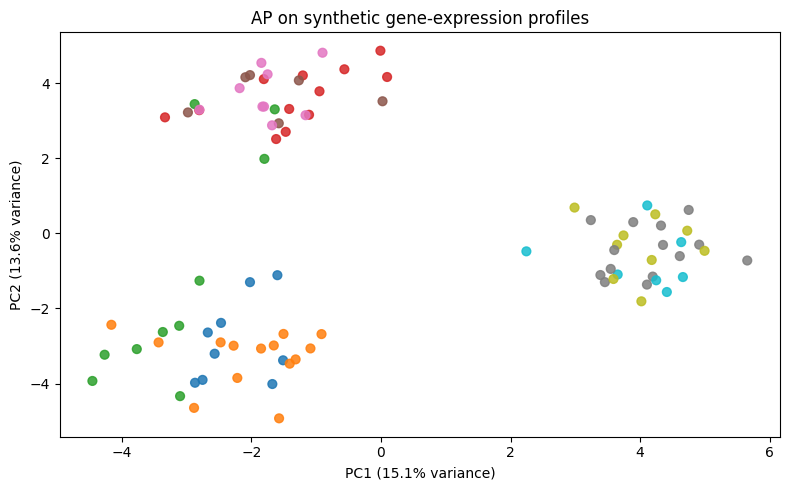

Variance explained by first two PCs: 28.8%


In [14]:
# Use PCA only to visualize the high-dimensional profiles in two dimensions.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
expression_2d = pca.fit_transform(X_expression_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    expression_2d[:, 0], expression_2d[:, 1],
    c=expression_labels, cmap="tab10", s=40, alpha=0.85
)
plt.title("AP on synthetic gene-expression profiles")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.tight_layout()
plt.show()
print("Variance explained by first two PCs:",
      f"{pca.explained_variance_ratio_.sum():.1%}")

### Bioinformatics interpretation checklist

1. Confirm measurement type and use appropriate normalization (raw RNA-seq counts should not be blindly standardized).
2. Inspect missing values, low-information features, outliers, and batch effects.
3. Justify feature selection and dimensionality reduction.
4. Run sensitivity analyses over preference and preprocessing choices.
5. Assess cluster stability and validate on independent samples where possible.
6. Do not call algorithmic clusters disease subtypes without external biological and clinical evidence.

The generated labels are algorithmic groupings, not diagnoses or validated molecular subtypes.

## 11. Precomputed similarity matrix

When `affinity="precomputed"`, supply a square **similarity** matrix where larger values mean more similar observations. Do not pass an ordinary distance matrix unchanged. A negative squared-distance matrix is one possible similarity choice.

In [15]:
# Demonstrate precomputed affinity on a small subset to limit memory use.
X_small = X[:60]
S_small = -pairwise_distances(X_small, metric="sqeuclidean")
small_off_diag = S_small[~np.eye(len(X_small), dtype=bool)]
pref_small = np.median(small_off_diag)

ap_precomputed = AffinityPropagation(
    affinity="precomputed", preference=pref_small,
    damping=0.75, max_iter=500, convergence_iter=20,
    random_state=RANDOM_STATE
).fit(S_small)

print("Precomputed-affinity clusters:", len(np.unique(ap_precomputed.labels_)))
print("Similarity matrix shape:", S_small.shape)

Precomputed-affinity clusters: 3
Similarity matrix shape: (60, 60)


## 12. Complexity, strengths, and limitations

### Strengths
- Does not require the cluster count as a direct input.
- Exemplars are actual observations and may be easier to inspect than abstract centroids.
- Supports custom similarity matrices via `affinity="precomputed"`.

### Limitations
- Pairwise similarity storage is typically \(O(n^2)\) in memory; computation can also be expensive.
- Results can be sensitive to `preference` and similarity scaling.
- Message passing can oscillate or fail to converge under some settings.
- High-dimensional data needs thoughtful preprocessing and similarity design.
- AP does not automatically identify noise as DBSCAN does.

## 13. Common mistakes

| Mistake | Better practice |
|---|---|
| Treating `preference` as a direct cluster-count setting | Sweep a meaningful range and inspect stability |
| Passing a distance matrix as a similarity matrix | Transform distances, for example to negative squared distances |
| Ignoring feature scale | Scale features when appropriate |
| Using AP on a huge dataset without checking memory | Reduce sample count or consider a more scalable algorithm |
| Ignoring iteration limits and warnings | Inspect `n_iter_`, warnings, and sensitivity |
| Claiming biological meaning from synthetic clusters | Validate on real data and independent cohorts |
| Comparing scores without considering DBSCAN noise labels | Report the noise fraction and interpret metrics carefully |

## 14. Practice exercises

### Beginner
1. Change the `random_state` in `make_blobs`. Does AP always find the same number of clusters?
2. Inspect `cluster_centers_indices_`. Why do these indices refer to rows in the original dataset?
3. Compare `damping=0.6` with `damping=0.9`.

### Intermediate
4. Plot cluster count across preference percentiles from 5 to 95.
5. Standardize the synthetic 2D data and compare the preference scale.
6. Repeat experiments over several seeds and summarize ARI and cluster-count variability.

### Advanced
7. Construct cosine similarities for normalized vectors and use `affinity="precomputed"`.
8. Compare clustering on synthetic expression data before and after removing low-variance genes.
9. Design a stability experiment by perturbing a subset of observations and comparing assignments on shared samples.
10. Explain when exemplar-based clustering may be preferable to centroid- or density-based clustering.

## 15. Quick reference

| Parameter / attribute | Meaning |
|---|---|
| `affinity` | `"euclidean"` or `"precomputed"` |
| `preference` | Self-similarity preference that influences exemplar selection |
| `damping` | Message smoothing; scikit-learn requires \(0.5\leq d<1\) |
| `max_iter` | Maximum message-passing iterations |
| `convergence_iter` | Stable iterations used by convergence checking |
| `labels_` | Cluster label for each observation |
| `cluster_centers_indices_` | Indices of selected exemplar observations |
| `cluster_centers_` | Exemplar feature vectors, when available |
| `n_iter_` | Number of iterations performed |

### Key takeaways
- AP discovers exemplars through responsibility and availability messages.
- The cluster count is not specified directly but is influenced by `preference`.
- Scaling, similarity design, damping, and convergence diagnostics matter.
- Use multiple metrics and domain validation; do not infer biological significance from clustering alone.

## 16. References

1. Frey, B. J., & Dueck, D. (2007). *Clustering by Passing Messages Between Data Points*. **Science, 315**(5814), 972–976. https://doi.org/10.1126/science.1136800
2. scikit-learn User Guide — Affinity Propagation: https://scikit-learn.org/stable/modules/clustering.html#affinity-propagation
3. scikit-learn API — `AffinityPropagation`: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AffinityPropagation.html
4. scikit-learn — Clustering performance evaluation: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation

**Suggested filename:** `Affinity_Propagation_Complete.ipynb`

Before publishing, run all cells from top to bottom in a fresh environment and review outputs. The notebook uses synthetic datasets and does not claim to analyze real patient data.